# Day 12: Chi-Square Test, ANOVA and Statistical Errors

## Learning Objectives

- Understand the Chi-Square Test.
- Perform a Chi-Square Goodness of Fit Test.
- Perform a Chi-Square Test of Independence.
- Understand Analysis of Variance (ANOVA).
- Perform a One-Way ANOVA test.
- Understand post-hoc testing.
- Understand Type I and Type II errors.
- Learn statistical significance and practical significance.

**Libraries:** NumPy, Pandas, Matplotlib, Seaborn, SciPy, Statsmodels

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

sns.set_theme(style="whitegrid")

## 1. Introduction to Chi-Square Test

The Chi-Square Test is a statistical test used to analyze categorical data.

It compares observed frequencies with expected frequencies.

Two commonly used types:

1. Chi-Square Goodness of Fit Test
2. Chi-Square Test of Independence

### 1. Goodness of Fit Test

Checks whether the observed distribution of a categorical variable matches an expected distribution.

Example:
A retailer expects customers to purchase four product categories equally. We can test whether actual purchases follow that expected distribution.

### 2. Test of Independence

Checks whether two categorical variables are associated with each other.

Example:
A company wants to investigate whether customer membership type is associated with purchase preference.

### Hypotheses

H0: The variables are independent, or the observed distribution matches the expected distribution.

H1: The variables are associated, or the observed distribution differs from the expected distribution.

## 2. Chi-Square Goodness of Fit Test

Business Scenario:

An e-commerce company expects its orders to be equally distributed across four product categories.

We collect the following observed order counts:

- Electronics: 120
- Clothing: 100
- Home: 90
- Beauty: 90

We want to check whether the observed order distribution differs from an equal distribution.

Hypotheses:

H0: Orders are equally distributed across all four categories.

H1: Orders are not equally distributed across all four categories.

Significance Level: 0.05

In [2]:
observed = np.array([120, 100, 90, 90])

total_orders = observed.sum()

expected = np.array([
    total_orders / 4
] * 4)

categories = [
    "Electronics",
    "Clothing",
    "Home",
    "Beauty"
]

comparison = pd.DataFrame({
    "Category": categories,
    "Observed": observed,
    "Expected": expected
})

comparison

,Category,Observed,Expected
0,Electronics,120,100.0
1,Clothing,100,100.0
2,Home,90,100.0
3,Beauty,90,100.0


In [3]:
chi2_statistic, p_value = stats.chisquare(
    f_obs=observed,
    f_exp=expected
)

alpha = 0.05

print("Chi-Square Statistic:", round(chi2_statistic, 4))
print("P-Value:", round(p_value, 4))

Chi-Square Statistic: 6.0
P-Value: 0.1116


In [4]:
if p_value <= alpha:
    print("Reject the Null Hypothesis.")
    print("The observed order distribution differs significantly from an equal distribution.")

else:
    print("Fail to reject the Null Hypothesis.")
    print("There is insufficient evidence that the order distribution differs from an equal distribution.")

Fail to reject the Null Hypothesis.
There is insufficient evidence that the order distribution differs from an equal distribution.


## 3. Chi-Square Test of Independence

The Chi-Square Test of Independence checks whether two categorical variables are associated.

Business Scenario:

An e-commerce company wants to understand whether membership type is associated with purchase preference.

We collect customer data and create a contingency table.

Rows represent membership types.

Columns represent purchase preferences.

Hypotheses:

H0: Membership type and purchase preference are independent.

H1: Membership type and purchase preference are associated.

Significance Level: 0.05

In [5]:
observed_table = pd.DataFrame(
    {
        "Electronics": [50, 80, 100],
        "Clothing": [90, 70, 60],
        "Home": [60, 50, 40]
    },
    index=["Silver", "Gold", "Platinum"]
)

observed_table

,Electronics,Clothing,Home
Silver,50,90,60
Gold,80,70,50
Platinum,100,60,40


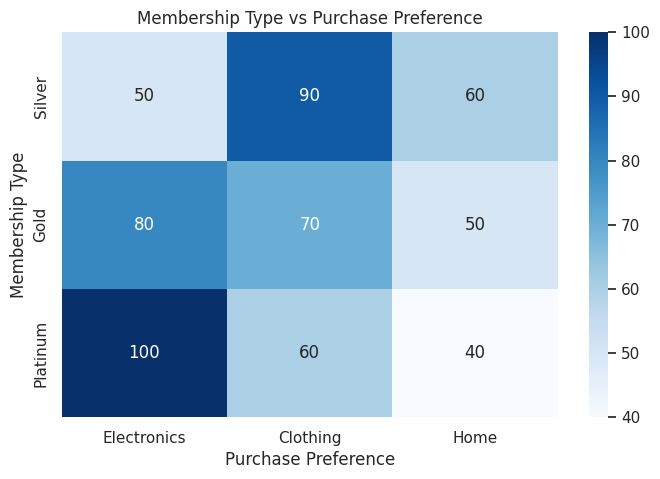

In [6]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    observed_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Membership Type vs Purchase Preference")
plt.xlabel("Purchase Preference")
plt.ylabel("Membership Type")

plt.show()

In [7]:
chi2_statistic, p_value, degrees_of_freedom, expected_table = (
    stats.chi2_contingency(observed_table)
)

print("Chi-Square Statistic:", round(chi2_statistic, 4))
print("Degrees of Freedom:", degrees_of_freedom)
print("P-Value:", round(p_value, 4))

print("\nExpected Frequencies:")
print(
    pd.DataFrame(
        expected_table,
        index=observed_table.index,
        columns=observed_table.columns
    ).round(2)
)

Chi-Square Statistic: 26.8854
Degrees of Freedom: 4
P-Value: 0.0

Expected Frequencies:
          Electronics  Clothing  Home
Silver          76.67     73.33  50.0
Gold            76.67     73.33  50.0
Platinum        76.67     73.33  50.0


In [8]:
if p_value <= alpha:
    print("Reject the Null Hypothesis.")
    print("There is evidence of an association between membership type and purchase preference.")

else:
    print("Fail to reject the Null Hypothesis.")
    print("There is insufficient evidence of an association between the two variables.")

Reject the Null Hypothesis.
There is evidence of an association between membership type and purchase preference.


## 4. Important Assumptions of Chi-Square Test

Before applying a Chi-Square Test, check the following:

1. Data should be frequency counts, not percentages or averages.
2. Categories should be mutually exclusive.
3. Observations should be independent.
4. Expected frequencies should generally be sufficiently large.

A common guideline for the Chi-Square Test is that expected cell frequencies should be at least 5.

If expected frequencies are too small, consider an appropriate alternative, such as Fisher's Exact Test for a suitable 2×2 table.

Important:
A statistically significant Chi-Square result indicates an association or difference, but it does not prove causation.

## 5. Introduction to ANOVA

ANOVA stands for Analysis of Variance.

It is used to compare the means of three or more independent groups.

Business Scenario:

A company wants to compare average sales generated by three different marketing campaigns.

- Campaign A
- Campaign B
- Campaign C

Instead of performing multiple pairwise T-tests, we can initially use One-Way ANOVA.

### Hypotheses

H0: All group population means are equal.

H1: At least one group population mean is different.

Significance Level: 0.05

Important:
A significant ANOVA result tells us that at least one group mean differs. It does not identify which groups differ.

## 6. One-Way ANOVA

One-Way ANOVA compares the means of independent groups based on one categorical factor.

Example:

We compare sales performance across three marketing campaigns.

The independent variable is Campaign.

The dependent variable is Sales.

ANOVA compares:
- Variation between groups.
- Variation within groups.

The F-statistic represents the ratio of these two sources of variation.

In [9]:
np.random.seed(42)

campaign_a = np.random.normal(
    loc=100,
    scale=12,
    size=40
)

campaign_b = np.random.normal(
    loc=110,
    scale=12,
    size=40
)

campaign_c = np.random.normal(
    loc=125,
    scale=12,
    size=40
)

sales_df = pd.DataFrame({
    "Sales": np.concatenate([
        campaign_a,
        campaign_b,
        campaign_c
    ]),
    "Campaign": (
        ["A"] * 40 +
        ["B"] * 40 +
        ["C"] * 40
    )
})

sales_df.head()

,Sales,Campaign
0,105.960570,A
1,98.340828,A
2,107.772262,A
3,118.276358,A
4,97.190160,A


In [10]:
group_summary = (
    sales_df
    .groupby("Campaign")["Sales"]
    .agg(
        ["count", "mean", "std"]
    )
)

group_summary.round(2)

,count,mean,std
Campaign,,,
A,40,97.38,11.43
B,40,109.65,11.58
C,40,125.12,10.35


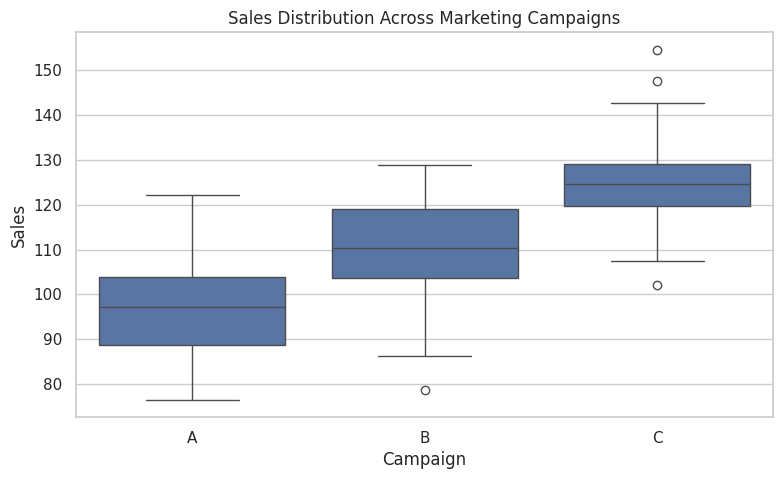

In [11]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sales_df,
    x="Campaign",
    y="Sales"
)

plt.title("Sales Distribution Across Marketing Campaigns")
plt.xlabel("Campaign")
plt.ylabel("Sales")

plt.show()

In [12]:
f_statistic, p_value = stats.f_oneway(
    campaign_a,
    campaign_b,
    campaign_c
)

print("F-Statistic:", round(f_statistic, 4))
print("P-Value:", round(p_value, 6))

F-Statistic: 62.3935
P-Value: 0.0


In [13]:
if p_value <= alpha:
    print("Reject the Null Hypothesis.")
    print("At least one campaign has a significantly different population mean.")

else:
    print("Fail to reject the Null Hypothesis.")
    print("There is insufficient evidence of a difference among the population means.")

Reject the Null Hypothesis.
At least one campaign has a significantly different population mean.


## 7. Post-Hoc Testing: Tukey's HSD

When ANOVA produces a statistically significant result, we know that at least one group mean differs.

However, ANOVA alone does not tell us which specific groups are different.

We use a post-hoc test such as Tukey's Honestly Significant Difference (HSD) to compare pairs of groups while controlling the family-wise error rate.

Examples:
- Campaign A vs Campaign B
- Campaign A vs Campaign C
- Campaign B vs Campaign C

Important:
Post-hoc testing is generally performed after a significant overall ANOVA result.

In [14]:
if p_value <= alpha:

    tukey_result = pairwise_tukeyhsd(
        endog=sales_df["Sales"],
        groups=sales_df["Campaign"],
        alpha=0.05
    )

    print(tukey_result)

else:
    print(
        "Overall ANOVA is not statistically significant. "
        "Post-hoc comparisons are not performed in this example."
    )

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     A      B  12.2751   0.0  6.3659 18.1844   True
     A      C  27.7457   0.0 21.8365  33.655   True
     B      C  15.4706   0.0  9.5613 21.3799   True
---------------------------------------------------


## 8. Assumptions of One-Way ANOVA

Before applying One-Way ANOVA, check the following assumptions:

### 1. Independence
Observations should be independent of each other.

### 2. Normality
The residuals within each group should be approximately normally distributed.

### 3. Homogeneity of Variance
The population variances of the groups should be approximately equal.

If the equal-variance assumption is not reasonable, Welch's ANOVA may be a better option.

Important:
ANOVA is reasonably robust to moderate departures from normality in many balanced designs, but serious assumption violations should be investigated.

In [15]:
levene_statistic, levene_p_value = stats.levene(
    campaign_a,
    campaign_b,
    campaign_c
)

print("Levene Statistic:", round(levene_statistic, 4))
print("P-Value:", round(levene_p_value, 4))

if levene_p_value > alpha:
    print("No statistically significant evidence of unequal variances.")

else:
    print("Evidence suggests that group variances may differ.")

Levene Statistic: 0.6576
P-Value: 0.52
No statistically significant evidence of unequal variances.


## 9. Statistical Errors

Statistical decisions are not always correct.

Two important errors can occur during hypothesis testing.

### Type I Error (False Positive)

Rejecting a Null Hypothesis that is actually true.

Example:
A company concludes that a new marketing campaign increases sales when it actually has no effect.

### Type II Error (False Negative)

Failing to reject a Null Hypothesis that is actually false.

Example:
A company fails to detect that a new marketing campaign really increases sales.

### Comparison

| Error | Meaning | Example |
|---|---|---|
| Type I | False Positive | Detecting an effect that does not exist |
| Type II | False Negative | Missing a real effect |

### Important Terms

- Alpha (α): Probability of a Type I error under the testing procedure.
- Beta (β): Probability of a Type II error for a specified alternative.
- Statistical Power: Probability of correctly rejecting a false Null Hypothesis.

Statistical Power = 1 - Beta

## 10. Statistical Significance vs Practical Significance

Statistical Significance:
Indicates whether the observed evidence is sufficiently strong against the Null Hypothesis.

Practical Significance:
Indicates whether the size of the observed effect is meaningful in the real business context.

Example:

A company tests whether a website change increases average order value.

The test gives a p-value of 0.001, but the average order value increases by only ₹1.

The result may be statistically significant, but the business impact may be too small to justify implementation costs.

Important:
Always consider effect size, business impact, costs, and context alongside the p-value.

## 11. Business Applications

### E-commerce
Check whether membership type is associated with product preference using a Chi-Square Test.

### Marketing
Compare the average sales performance of multiple marketing campaigns using ANOVA.

### Banking
Analyze whether customer categories are associated with loan approval outcomes.

### Retail
Compare average sales across multiple store locations.

### Human Resources
Compare employee performance across different training programs.

Statistical tests help analysts evaluate business differences and relationships using data.

## 12. Quick Revision

| Concept | Purpose |
|---|---|
| Chi-Square Goodness of Fit | Checks whether observed frequencies match an expected distribution |
| Chi-Square Test of Independence | Checks association between two categorical variables |
| ANOVA | Compares means of three or more independent groups |
| F-Statistic | Ratio of between-group to within-group variation in ANOVA |
| Post-Hoc Test | Identifies which group pairs differ after significant ANOVA |
| Type I Error | False positive |
| Type II Error | False negative |
| Statistical Power | Probability of correctly rejecting a false H0 |
| Practical Significance | Real-world importance of an observed effect |

## 13. Interview Questions and Answers

**Q1. What is a Chi-Square Test?**  
It is a statistical test used to analyze categorical data by comparing observed and expected frequencies.

**Q2. What is the difference between Goodness of Fit and Test of Independence?**  
Goodness of Fit checks whether a categorical distribution matches an expected distribution. Test of Independence checks whether two categorical variables are associated.

**Q3. What is a contingency table?**  
It is a table that displays frequency counts for combinations of categorical variables.

**Q4. What is ANOVA?**  
ANOVA is a statistical method used to compare the means of three or more independent groups.

**Q5. Why do we use ANOVA instead of multiple T-tests?**  
Repeated T-tests increase the chance of making a Type I error. ANOVA provides an overall test of group mean differences.

**Q6. What does a significant ANOVA result indicate?**  
It indicates that at least one population group mean differs from the others.

**Q7. What is a post-hoc test?**  
It is a follow-up test used to identify which specific group pairs differ after a significant ANOVA result.

**Q8. What is Tukey's HSD?**  
It is a post-hoc method that compares group means while controlling the family-wise error rate.

**Q9. What is Type I Error?**  
Rejecting a Null Hypothesis that is actually true.

**Q10. What is Type II Error?**  
Failing to reject a Null Hypothesis that is actually false.

**Q11. What is statistical power?**  
It is the probability of correctly rejecting a false Null Hypothesis.

**Q12. What is the difference between statistical and practical significance?**  
Statistical significance concerns the strength of evidence, while practical significance concerns whether the effect matters in real-world terms.

## 14. Practice Tasks

1. Create observed frequencies for five product categories and perform a Chi-Square Goodness of Fit Test.
2. Create a contingency table for customer gender and membership type. Perform a Chi-Square Test of Independence.
3. Compare average sales across four stores using One-Way ANOVA.
4. Perform Tukey's HSD after a statistically significant ANOVA result.
5. Check the equal-variance assumption using Levene's Test.
6. Explain Type I and Type II errors using a banking example.
7. Explain the difference between statistical significance and practical significance.
8. Explain why multiple T-tests can increase the risk of Type I errors.

Try to solve these tasks independently.

## Day 12 — Key Takeaways

- Chi-Square Tests are used for categorical frequency data.
- Goodness of Fit checks an observed distribution against an expected distribution.
- The Test of Independence checks the association between two categorical variables.
- ANOVA compares means across three or more independent groups.
- Tukey's HSD helps identify which group pairs differ after significant ANOVA.
- Type I and Type II errors represent different incorrect statistical decisions.
- Statistical significance does not automatically mean practical importance.

### Next Topic: Day 13

Covariance, Correlation and Linear Regression.